# First analysis to load AV_Dome data from RDSS and get Learning curves 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# import seaborn as sns
import os
from pathlib import Path
import xarray as xr


In [ ]:
# This assumes that you mounted the AV_Dome prject folder as a mapped network drive "Z:". If you mounted it to a different location, please change the path below.
root_folder = Path(r"Z:\AV_Dome")

# list all available subjects:
dirs = [p for p in root_folder.iterdir() if p.is_dir()]

all_subjects = []
for i in dirs:
    subject = i.name.split("sub-")[-1]
    all_subjects.append(subject)
#

# ## OVERWRITE FOR NOW!!!
all_subjects = ["GN011"]

In [ ]:
from modules.loading_functions import load_sessions

df = load_sessions(root_folder, all_subjects)

35
Index(['Seconds', 'Response', 'Item1', 'trialType', 'RewardProbability',
       'IsRewarded', 'IsRepeat', 'RepeatCount', 'Item2', 'ITI',
       'autoRewardProbability', 'autoReward', 'RewardSizeInUl',
       'visualAzimuth', 'visualContrast', 'visualPhase', 'audioAzimuth',
       'OptogeneticEnabled', 'OptogeneticCondition', 'OptogeneticDelay',
       'OptogeneticDuration', 'OptogeneticPower', 'openLoopDuration',
       'closedLoopDuration', 'visualElevation', 'visualGaussianWindowSigma',
       'visualFlickerFrequency', 'visualOrientation', 'visualSpatialFrequency',
       'visualTemporalFrequency', 'visualFlickerFrequency', 'audioElevation',
       'audioFlickerFrequency', 'session_path', 'dateTime'],
      dtype='str')
35
Index(['Seconds', 'Response', 'Item1', 'trialType', 'RewardProbability',
       'IsRewarded', 'IsRepeat', 'RepeatCount', 'Item2', 'ITI',
       'autoRewardProbability', 'autoReward', 'RewardSizeInUl',
       'visualAzimuth', 'visualContrast', 'visualPhase', 'aud

In [ ]:
# Inspect df:
# print(df.iloc[0:100, 30:])

In [ ]:
# [df.session_path[1742:], df.session_id[1742:], df.training_stage[1742:]]

In [ ]:
# # df.iloc[:, 1]
# df.rename_col_by_index(1, "A")

# df.rename(columns={df.columns[1]: "user_id",
#     df.columns[1]: "full_name",

AttributeError: 'DataFrame' object has no attribute 'rename_col_by_index'

In [6]:
# This is where loading is done and anayysis can start...

overall_df = df.copy()

# Current results output doesn't include both_spouts! Need to investigate and add this filter in the future, but for now, skip that mask.
trialMask = ((df.response == "Correct") | (df.response == "Incorrect"))  # & (df.training_stage == 0)
df = df.loc[trialMask]

correctResponses = (df.response == "Correct").astype(int)
print(np.mean(correctResponses))  # Overall accuracy


AttributeError: 'DataFrame' object has no attribute 'response'

0.8378378378378378
0.43703703703703706
0.41333333333333333


0.3935389133627019
0.44510385756676557
0.6646525679758308
0.6694630872483222
0.7194029850746269
0.7120253164556962
0.7575757575757576


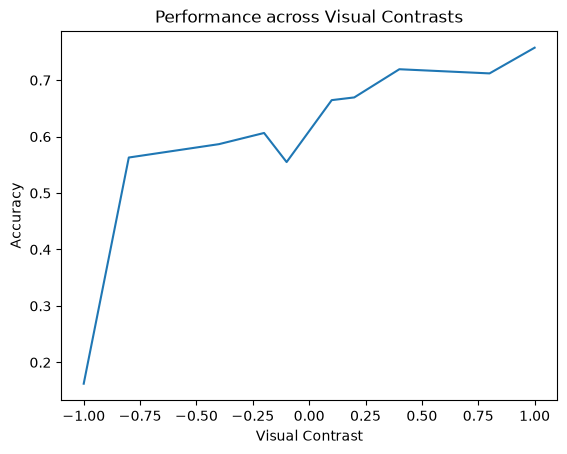

In [ ]:
visual_contrasts = np.unique(df.visualContrast).astype(float)  # loaded as str...
visual_contrasts = np.concatenate((-visual_contrasts, visual_contrasts))  # represent left as negative contrasts
visual_contrasts = np.sort(visual_contrasts)  # ascending order

data = xr.Dataset()
ds = xr.Dataset()
for contrast in visual_contrasts:
    side_str = "Left" if contrast < 0 else "Right"
    df_contrast = df[(df.visualContrast.astype(float) == np.abs(contrast)) & (df.target_side == side_str)]
    data[f"contrast_{contrast}"] = df_contrast
    
    correctResponses = (df_contrast.response == "Correct").astype(int)
    print(np.mean(correctResponses))  # accuracy
    ds[f"contrast_{contrast}"] = 1 - np.mean(correctResponses) if contrast < 0 else np.mean(correctResponses)
#

# data
# ds

plt.plot(visual_contrasts, ds.to_array().values)
plt.xlabel("Visual Contrast")
plt.ylabel("Accuracy")
plt.title("Performance across Visual Contrasts")
plt.show()
